In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plotly.io as pio
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import HTML
pio.renderers.default = 'jupyterlab' #'iframe' # or 'notebook' or 'colab' or 'jupyterlab' or 'browser'



In [ ]:
#基本的figure 和基本layout绘制图形
fig = go.Figure(
    data=[go.Bar(x=['A','B'], y=[10,20],name='test')],
    layout=go.Layout(title='Example Bar',showlegend=True)
)
fig.show()

In [ ]:
#ndarray多列排序
arr = np.ones((7,4))

arr[::2,0:1] = 2
arr[:,1] = range(1,len(arr)+1)
np.argsort(arr[:,0])
def get_rank_by_argsort(arr):
    """
    使用两次argsort获取排名
    """
    # 第一次argsort: 获取排序后的索引
    sorted_indices = np.argsort(arr)
    print(sorted_indices)
    # 第二次argsort: 获取每个元素在排序后的位置（排名）
    ranks = np.argsort(sorted_indices)
    
    return ranks
get_rank_by_argsort(arr[:,0])




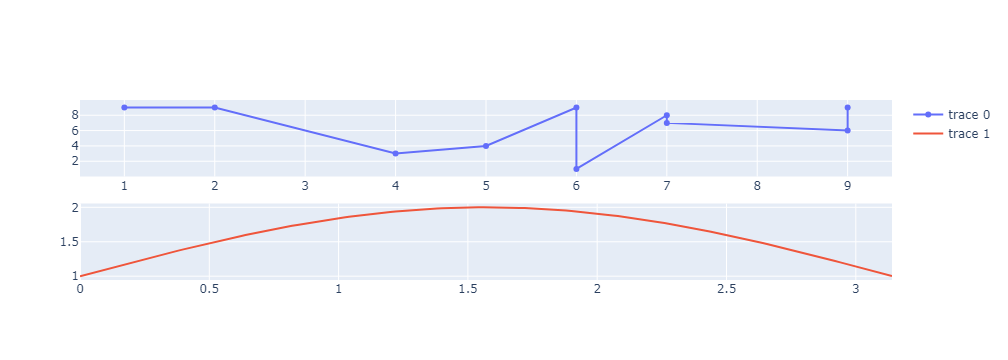

In [24]:
#在多个字画布中画图形：
from plotly.subplots import make_subplots
fig = make_subplots(rows=2, cols=1)
arr = np.column_stack((np.random.randint(1,10,10),np.random.randint(1,10,10) ))
arr = arr[np.argsort(arr[:,0])]

fig.add_trace(go.Scatter(x=arr[:,0] ,y=arr[:,1] ),row=1,col=1)
x = np.arange(0,np.pi,0.02)
y = np.sin(x)+1
fig.add_trace(go.Scatter(x=x,y=y),row=2,col=1)


In [16]:
for i,trace in enumerate(fig.data):
    print(trace.name)

None
None


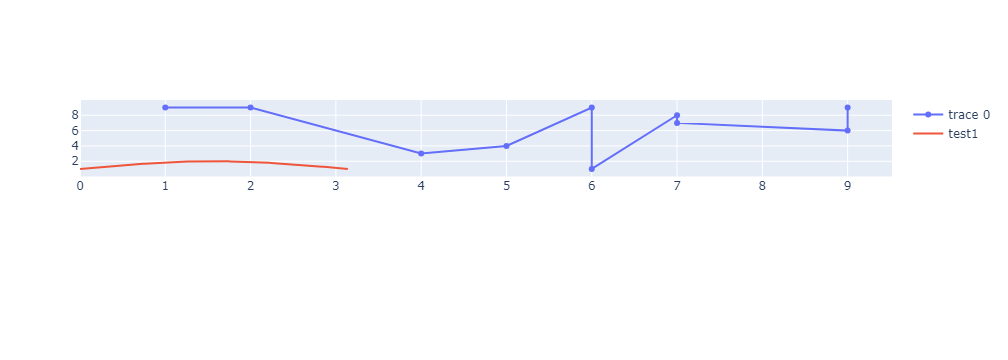

In [31]:
fig.data[1].name='test1'

In [32]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 创建包含多个子图的图形
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=('子图1', '子图2', '子图3', '子图4')
)

# 添加多个轨迹到不同子图
fig.add_trace(go.Scatter(x=[1, 2, 3], y=[4, 5, 6], name="轨迹1"), row=1, col=1)
fig.add_trace(go.Bar(x=[1, 2, 3], y=[4, 5, 6], name="轨迹1.1"), row=1, col=1)
fig.add_trace(go.Bar(x=[1, 2, 3], y=[3, 2, 1], name="轨迹2"), row=1, col=2)
fig.add_trace(go.Scatter(x=[1, 2, 3], y=[2, 3, 4], name="轨迹3"), row=2, col=1)
fig.add_trace(go.Bar(x=[1, 2, 3], y=[5, 3, 1], name="轨迹4"), row=2, col=2)

print(f"删除前轨迹数量: {len(fig.data)}")

# 删除特定索引的轨迹（例如删除第2个轨迹）
# if len(fig.data) > 1:
#     fig.data = list(fig.data[:1]) + list(fig.data[2:])

# print(f"删除后轨迹数量: {len(fig.data)}")

删除前轨迹数量: 5


In [35]:
fig.data = list(fig.data[:1]) + list(fig.data[2:])

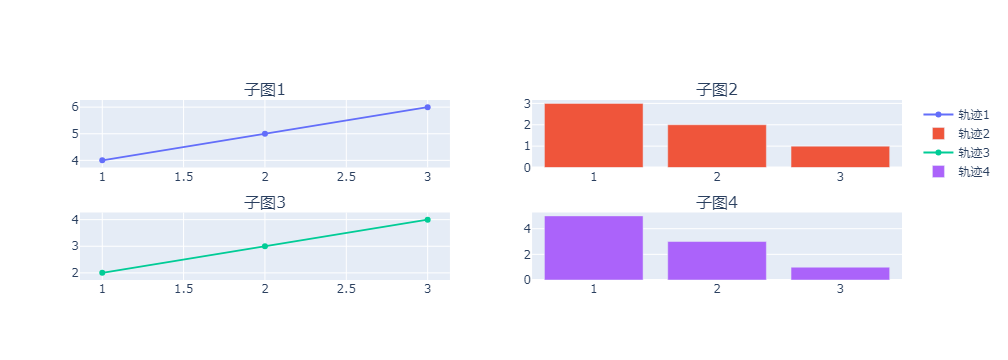

In [36]:
fig

In [6]:
fig = make_subplots(rows=2, cols=1)

np.random.seed(42)
x = np.arange(1, 31)
y1 = np.random.randn(30).cumsum()
y2 = np.random.rand(30) * 100
categories = np.random.choice(['A', 'B', 'C'], 30)

# 1. 创建子图画布
# fig = make_subplots(
#     rows=2, cols=2,  # 2行2列布局
#     specs=[[{"type": "scatter"}, {"type": "bar"}],  # 第一行：散点图+柱状图
#            [{"type": "box", "colspan": 2}, None]],  # 第二行：跨两列的箱线图
#     subplot_titles=("折线图", "柱状图", "分类箱线图")  # 子图标题
# )

# 2. 创建Plotly Express图表（但不直接显示）
line_fig = px.line(x=x, y=y1, title="折线图")
bar_fig = px.bar(x=x, y=y2, color=categories, title="柱状图")
box_fig = px.box(x=categories, y=y2, color=categories, title="分类箱线图")






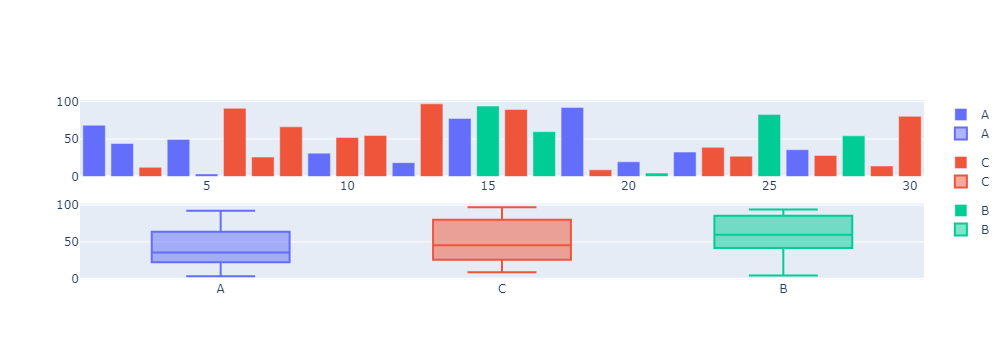

In [11]:
# fig.add_trace(line_fig.data[0], row=1, col=1)
fig.data=[]
for trace in bar_fig.data:
    fig.add_trace(trace,row=1,col=1)
for trace in box_fig.data:
    fig.add_trace(trace,row=2,col=1)
fig.show()

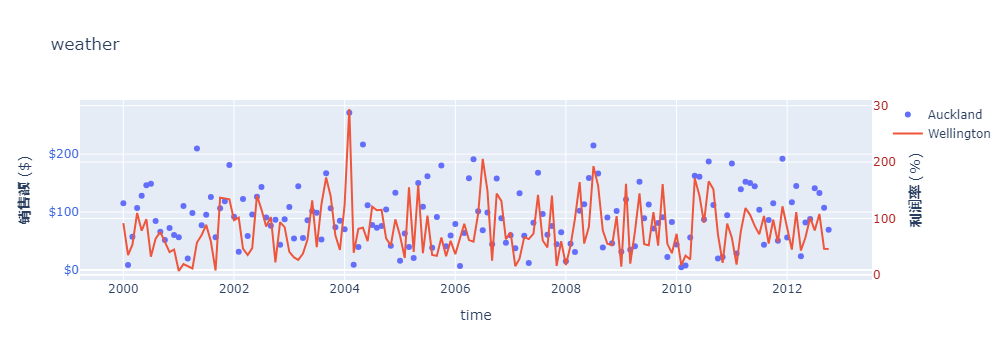

In [34]:
#go一画线和画散点，双坐标

data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
# data.head()
line1 = go.Scatter(x=data['DATE'],y=data['Auckland'],name='Auckland',mode='markers') #散点
line2 = go.Scatter(x=data['DATE'],y=data['Wellington'],name='Wellington',yaxis="y2")
# line3 = px.scatter(data,x='DATE',y='Wellington')

fig = go.Figure([line1])
# fig.update_yaxes(secondary_y=True)
fig.add_trace(line2)
# ?怎么画双Y轴

fig.update_layout(title='weather',
                  xaxis_title='time',
                  # 主Y轴配置
    yaxis=dict(
        title="<b>销售额</b> ($)",
        # titlefont=dict(color="royalblue"),
        tickfont=dict(color="royalblue"),
        tickprefix="$",
        side="left"  # 左侧
    ),
     # 次Y轴配置
    yaxis2=dict(
        title="<b>利润率</b> (%)",
        # titlefont=dict(color="firebrick"),
        tickfont=dict(color="firebrick"),
        # tickformat=".0%",
        anchor="x",          # 锚定在x轴上
        overlaying="y",      # 覆盖在第一个Y轴上
        side="right",        # 右侧
        position=1.0         # 位置（0-1）
    ) 
)
fig.show()
# HTML(fig.to_html())



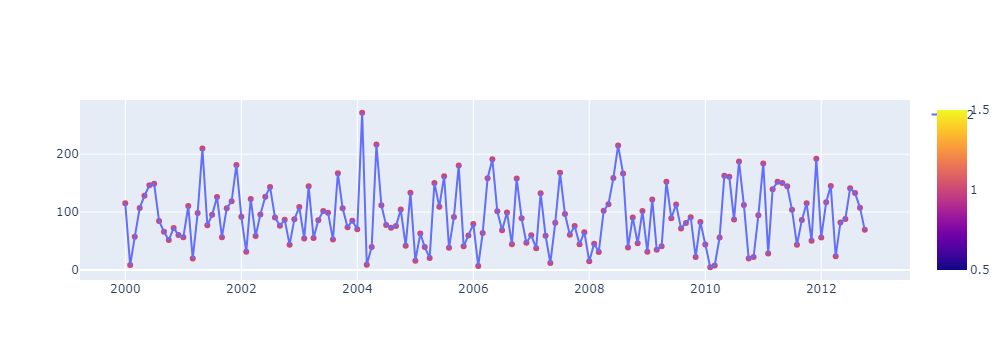

In [35]:
# px画线和散点：
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
data['Color1'] = 1
data['Color2'] = 2
fig1 = px.scatter(data,x='DATE',y='Auckland',color='Color1')
fig2 = px.line(data,x='DATE',y='Auckland',color='Color2')
fig = go.Figure(data=fig1.data + fig2.data) #怎么实现双Y轴"secondary_y": True
fig.show()
#可以使用 color="sex",  # 颜色和标记来同时区分  symbol="smoker"


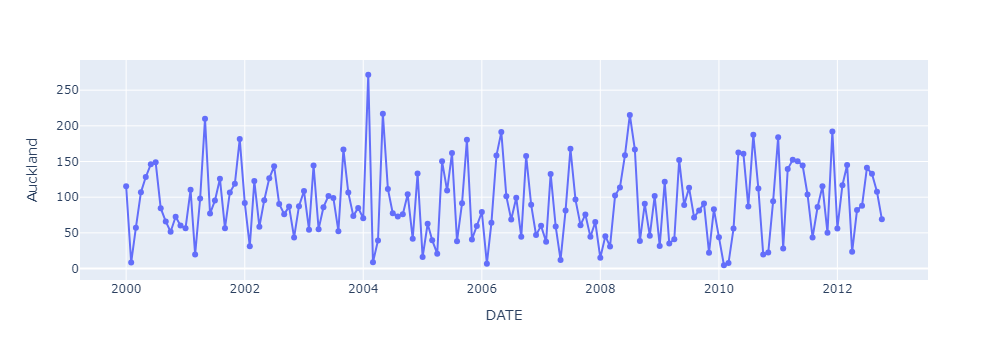

In [3]:
#测试px画线同时显示点：
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
data['Width'] = 12
fig = px.line(data,x='DATE',y='Auckland',markers=True)
fig.show()

In [4]:
data

,DATE,Auckland,Christchurch,Dunedin,Hamilton,Wellington,Width
0,2000-01,115.4,47.2,174.8,96.2,91.8,12
1,2000-02,8.4,25.2,41,8.2,35.2,12
2,2000-03,57.2,60.8,74.2,33.8,53.4,12
3,2000-04,106.8,58.2,50,129.6,109.8,12
4,2000-05,128.2,62.0,'-,98.2,78.2,12
...,...,...,...,...,...,...,...
149,2012-06,88.0,111.2,71.2,92,101.4,12
150,2012-07,141.2,92.1,47.4,223.8,78.8,12
151,2012-08,132.8,93.2,103.2,147,108.0,12
152,2012-09,107.6,32.4,52.6,89.9,46.2,12


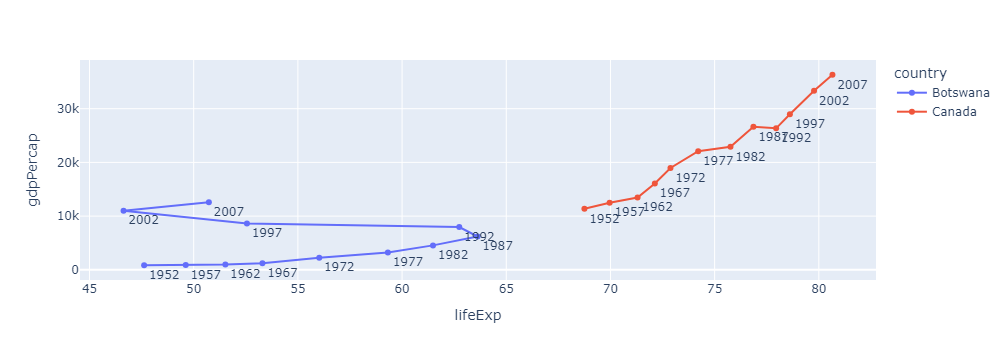

In [5]:
#px同时画线和点
df = px.data.gapminder().query("country in ['Canada', 'Botswana']")
df.sort_values(by="year")
fig = px.line(df, x="lifeExp", y="gdpPercap", color="country", text="year")
fig.update_traces(textposition="bottom right")
fig.show()

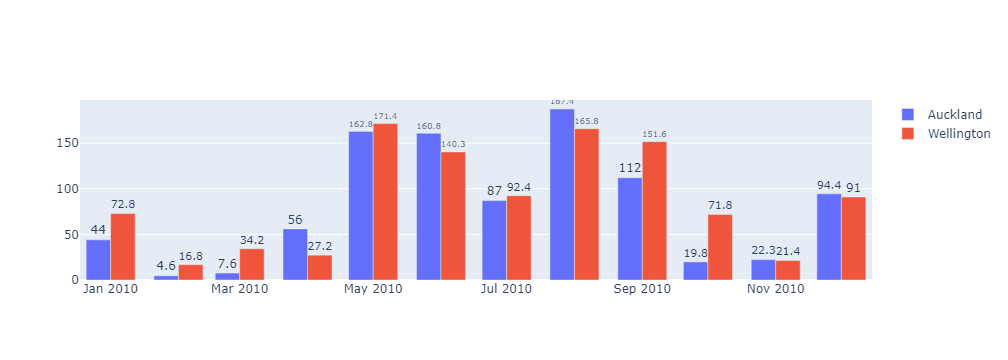

In [6]:
#go画条形图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
data2010 = data[(data['DATE']>='2010-01') & (data['DATE'] < '2011-01')]
bar1 = go.Bar(x=data2010['DATE'],y = data2010['Auckland'],text=data2010['Auckland'],textposition='outside',name='Auckland') #inside,outside
bar2 = go.Bar(x=data2010['DATE'],y = data2010['Wellington'],text=data2010['Wellington'],textposition='outside',name='Wellington')
fig = go.Figure([bar1,bar2])
fig.show()


C:\Users\kim\AppData\Local\Temp\ipykernel_16284\3968611149.py:5: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.

C:\Users\kim\AppData\Local\Temp\ipykernel_16284\3968611149.py:9: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.



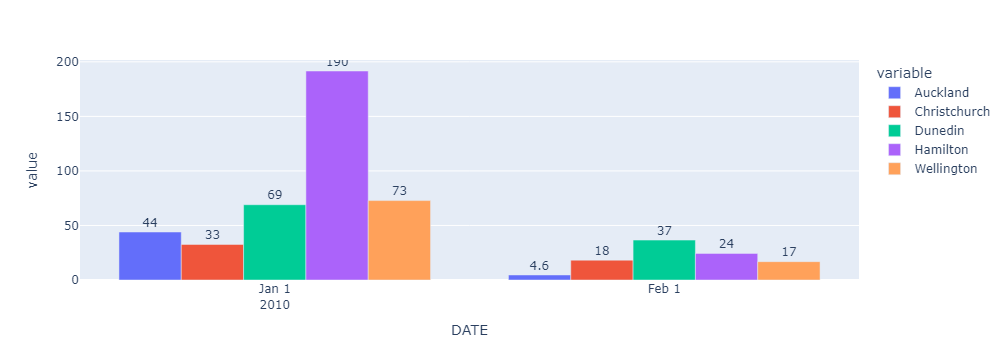

In [7]:
# px画条形图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
# data = data[(data['DATE']>='2010-01') & (data['DATE'] < '2011-01')]
data = data.query("DATE >= '2010-01' & DATE < '2010-03'")
f = data.Hamilton.str.contains("^[-+]?([0-9]+(\.[0-9]*)?|\.[0-9]+)$")
# print(data[~f]) #17 和41 行是非数值
# data = data[(data['Dunedin'] == '-') | (data['Hamilton'] == '-')]
data.loc[data[~f].index,'Hamilton'] = np.nan
f = data['Dunedin'].str.contains("^[-+]?([0-9]+(\.[0-9]*)?|\.[0-9]+)$")
data.loc[data[~f].index,'Dunedin'] = np.nan
data = data.astype({'Dunedin':'float64','Hamilton':'float64'},copy=False)
fig = px.bar(data,x='DATE',y = list(data.columns.drop('DATE')),barmode = 'group')
# fig.update_traces(textposition='top center',textfont={'color': '#bebebe', 'size':14})
fig.update_traces(texttemplate='%{value:.2s}',   # 显示的整数位数：示例为2位
                  textposition='outside')   # 文本显示位置：['inside', 'outside', 'auto', 'none']
# fig.update_layout(uniformtext_minsize=8,  # 显示文本字体大小
#                   uniformtext_mode='show')  #  文本显示4种模式：[False, 'hide', 'show']

# fig.update_layout(height=800,title_text='GDP and Life Expectancy (Americas, 2007)')
# barmode='overlay'|'group'  orientation='h' hover_data=["tip", "size"], text_auto=True
fig.show()

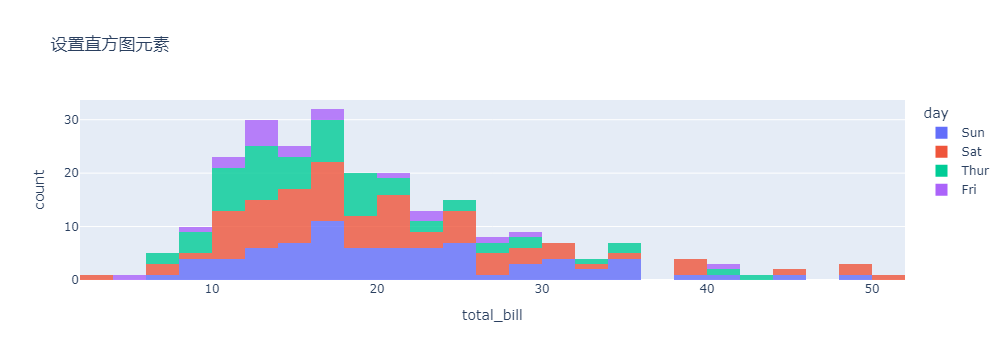

In [8]:
#px画直方图
data = px.data.tips()
fig = px.histogram(data, x="total_bill",
    title='设置直方图元素',   # 标题
    labels={'tip':'小费'},   # x轴label设置
    opacity=0.8,  # 图形透明度
    color="day" 
#     log_y=True,  # 取值的对数 
#     color_discrete_sequence=['firebrick'] # 颜色选择
    )
fig.show()

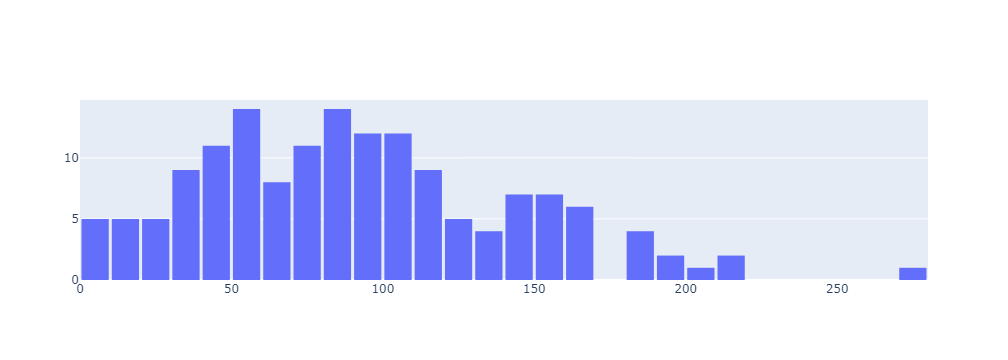

In [9]:
#go直方图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
hist = go.Histogram(x=data['Auckland'],xbins={'size':10})
fig = go.Figure(hist)
fig.update_layout(bargap=0.1)
fig.show()




In [12]:
#go的散点图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/iris.csv')
data.head()
# data.groupby('Name').count().index
name_to_color = {'Iris-setosa':0, 'Iris-versicolor':1, 'Iris-virginica':2}
data['color'] = data['Name'].map(name_to_color)
# data.head()
points = go.Scatter(x = data['SepalLength'], y = data['SepalWidth'],
                    mode='markers',marker = {'color':data['color']})
fig = go.Figure(points)
fig.show()

In [29]:
#px的散点图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/iris.csv')
# fig = px.scatter(data,x='SepalLength',y='SepalWidth',color='Name')
# fig.show()
fig = px.scatter_matrix(data,color='Name',dimensions=['SepalLength','SepalWidth','PetalLength','PetalWidth'])
fig.show()

In [6]:
#go+px画3D散点图
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/3d-line1.csv')
line = go.Scatter3d(x=data['x'],y=data['y'],z=data['z'],mode='markers',marker={'size':3,'color':'red'})  #mode:lines,markers
fig = go.Figure(line)
fig.show()
data['size'] = 2
fig = px.scatter_3d(data,x='x',y='y',z='z',color='color',size='size') #,marker={'size':2}
fig.show()

In [168]:
#px画面图
px?

In [ ]:
#go画面图
x = np.arange(-5,6)
y = np.arange(-5,6)
xv,yv = np.meshgrid(x,y)
z = xv **2 + yv**2
surface = go.Surface(x=xv,y=yv,z=z)
fig = go.Figure(surface)
fig.show()


In [18]:
#动画柱状图
import plotly.express as px

df = px.data.gapminder()

fig = px.bar(df, x="continent", y="pop", color="continent",
  animation_frame="year", animation_group="country", range_y=[0,4000000000])
fig.show()

In [2]:
#动画散点图
import plotly.express as px
df = px.data.gapminder()
fig = px.scatter(df, x="gdpPercap", y="lifeExp", animation_frame="year", animation_group="country",
           size="pop", color="continent", hover_name="country",
           log_x=True, size_max=55, range_x=[100,100000], range_y=[25,90])
fig.show()

In [4]:
df[df.continent=='Asia']

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4
...,...,...,...,...,...,...,...,...
1675,"Yemen, Rep.",Asia,1987,52.922,11219340,1971.741538,YEM,887
1676,"Yemen, Rep.",Asia,1992,55.599,13367997,1879.496673,YEM,887
1677,"Yemen, Rep.",Asia,1997,58.020,15826497,2117.484526,YEM,887
1678,"Yemen, Rep.",Asia,2002,60.308,18701257,2234.820827,YEM,887


In [3]:
#一帧帧的显示动画
import plotly.graph_objects as go

fig = go.Figure(
    data=[go.Scatter(x=[0, 1], y=[0, 1])],
    layout=go.Layout(
        xaxis=dict(range=[0, 5], autorange=False),
        yaxis=dict(range=[0, 5], autorange=False),
        title="Start Title",
        updatemenus=[dict(
            type="buttons",
            buttons=[dict(label="Play",
                          method="animate",
                          args=[None])])]
    ),
    frames=[go.Frame(data=[go.Scatter(x=[1, 2], y=[1, 2])]),
            go.Frame(data=[go.Scatter(x=[1, 4], y=[1, 4])]),
            go.Frame(data=[go.Scatter(x=[3, 4], y=[3, 4])],
                     layout=go.Layout(title_text="End Title"))]
)

fig.show()

In [17]:
#沿曲线运动的点

import plotly.graph_objects as go

import numpy as np

# Generate curve data
t = np.linspace(-1, 1, 100)
x = t + t ** 2
y = t - t ** 2
xm = np.min(x) - 1.5
xM = np.max(x) + 1.5
ym = np.min(y) - 1.5
yM = np.max(y) + 1.5
N = 50
s = np.linspace(-1, 1, N)
xx = s + s ** 2
yy = s - s ** 2


# Create figure
fig = go.Figure(
    data=[
          go.Scatter(x=x, y=y,
                     mode="lines",
                     line=dict(width=2, color="blue"))
          ,
          go.Scatter(x=x, y=y,
                     mode="lines",
                     line=dict(width=2, color="blue"))
         ],
    layout=go.Layout(
        xaxis=dict(range=[xm, xM], autorange=False, zeroline=False),
        yaxis=dict(range=[ym, yM], autorange=False, zeroline=False),
        title_text="Kinematic Generation of a Planar Curve", hovermode="closest",
        updatemenus=[dict(type="buttons",
                          buttons=[dict(label="Play",
                                        method="animate",
                                        args=[None]),{
                "args": [[None], {"frame": {"duration": 0, "redraw": False},
                                  "mode": "immediate",
                                  "transition": {"duration": 0}}],
                "label": "Pause",
                "method": "animate"
            }
                                  ])]),
    frames=[go.Frame(
        data=[go.Scatter(
            x=[xx[k]],
            y=[yy[k]],
            mode="markers",
            marker=dict(color="red", size=10))])

        for k in range(N)]
)

fig.show()

In [7]:
#沿曲线运动的切线
import plotly.graph_objects as go
import numpy as np

# Generate curve data
t = np.linspace(-1, 1, 100)
x = t + t ** 2
y = t - t ** 2
xm = np.min(x) - 1.5
xM = np.max(x) + 1.5
ym = np.min(y) - 1.5
yM = np.max(y) + 1.5
N = 50
s = np.linspace(-1, 1, N)
xx = s + s ** 2
yy = s - s ** 2
vx = 1 + 2 * s
vy = 1 - 2 * s  # v=(vx, vy) is the velocity
speed = np.sqrt(vx ** 2 + vy ** 2)
ux = vx / speed  # (ux, uy) unit tangent vector, (-uy, ux) unit normal vector
uy = vy / speed

xend = xx + ux  # end coordinates for the unit tangent vector at (xx, yy)
yend = yy + uy

xnoe = xx - uy  # end coordinates for the unit normal vector at (xx,yy)
ynoe = yy + ux


# Create figure
fig = go.Figure(
    data=[go.Scatter(x=x, y=y,
                     name="frame",
                     mode="lines",
                     line=dict(width=2, color="blue")),
          go.Scatter(x=x, y=y,
                     name="curve",
                     mode="lines",
                     line=dict(width=2, color="blue"))
          ],
    layout=go.Layout(width=600, height=600,
                     xaxis=dict(range=[xm, xM], autorange=False, zeroline=False),
                     yaxis=dict(range=[ym, yM], autorange=False, zeroline=False),
                     title="Moving Frenet Frame Along a Planar Curve",
                     hovermode="closest",
                     updatemenus=[dict(type="buttons",
                                       buttons=[dict(label="Play",
                                                     method="animate",
                                                     args=[None])])]),

    frames=[go.Frame(
        data=[go.Scatter(
            x=[xx[k], xend[k], None, xx[k], xnoe[k]],
            y=[yy[k], yend[k], None, yy[k], ynoe[k]],
            mode="lines",
            line=dict(color="red", width=2))
        ]) for k in range(N)]
)

fig.show()

In [11]:
#人口 GDP动画演变
import plotly.graph_objects as go

import pandas as pd

# url = "https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv"
# dataset = pd.read_csv(url)
dataset = px.data.gapminder()

years = ["1952", "1962", "1967", "1972", "1977", "1982", "1987", "1992", "1997", "2002",
         "2007"]

# make list of continents
continents = []
for continent in dataset["continent"]:
    if continent not in continents:
        continents.append(continent)
# make figure
fig_dict = {
    "data": [],
    "layout": {},
    "frames": []
}

# fill in most of layout
fig_dict["layout"]["xaxis"] = {"range": [30, 85], "title": "Life Expectancy"}
fig_dict["layout"]["yaxis"] = {"title": "GDP per Capita", "type": "log"}
fig_dict["layout"]["hovermode"] = "closest"
fig_dict["layout"]["updatemenus"] = [
    {
        "buttons": [
            {
                "args": [None, {"frame": {"duration": 500, "redraw": False},
                                "fromcurrent": True, "transition": {"duration": 300,
                                                                    "easing": "quadratic-in-out"}}],
                "label": "Play",
                "method": "animate"
            },
            {
                "args": [[None], {"frame": {"duration": 0, "redraw": False},
                                  "mode": "immediate",
                                  "transition": {"duration": 0}}],
                "label": "Pause",
                "method": "animate"
            }
        ],
        "direction": "left",
        "pad": {"r": 10, "t": 87},
        "showactive": False,
        "type": "buttons",
        "x": 0.1,
        "xanchor": "right",
        "y": 0,
        "yanchor": "top"
    }
]

sliders_dict = {
    "active": 0,
    "yanchor": "top",
    "xanchor": "left",
    "currentvalue": {
        "font": {"size": 20},
        "prefix": "Year:",
        "visible": True,
        "xanchor": "right"
    },
    "transition": {"duration": 300, "easing": "cubic-in-out"},
    "pad": {"b": 10, "t": 50},
    "len": 0.9,
    "x": 0.1,
    "y": 0,
    "steps": []
}

# make data
year = 1952
for continent in continents:
    dataset_by_year = dataset[dataset["year"] == year]
    dataset_by_year_and_cont = dataset_by_year[
        dataset_by_year["continent"] == continent]

    data_dict = {
        "x": list(dataset_by_year_and_cont["lifeExp"]),
        "y": list(dataset_by_year_and_cont["gdpPercap"]),
        "mode": "markers",
        "text": list(dataset_by_year_and_cont["country"]),
        "marker": {
            "sizemode": "area",
            "sizeref": 200000,
            "size": list(dataset_by_year_and_cont["pop"])
        },
        "name": continent
    }
    fig_dict["data"].append(data_dict)

# make frames
for year in years:
    frame = {"data": [], "name": str(year)}
    for continent in continents:
        dataset_by_year = dataset[dataset["year"] == int(year)]
        dataset_by_year_and_cont = dataset_by_year[
            dataset_by_year["continent"] == continent]

        data_dict = {
            "x": list(dataset_by_year_and_cont["lifeExp"]),
            "y": list(dataset_by_year_and_cont["gdpPercap"]),
            "mode": "markers",
            "text": list(dataset_by_year_and_cont["country"]),
            "marker": {
                "sizemode": "area",
                "sizeref": 200000,
                "size": list(dataset_by_year_and_cont["pop"])
            },
            "name": continent
        }
        frame["data"].append(data_dict)

    fig_dict["frames"].append(frame)
    slider_step = {"args": [
        [year],
        {"frame": {"duration": 300, "redraw": False},
         "mode": "immediate",
         "transition": {"duration": 300}}
    ],
        "label": year,
        "method": "animate"}
    sliders_dict["steps"].append(slider_step)


fig_dict["layout"]["sliders"] = [sliders_dict]

fig = go.Figure(fig_dict)

fig.show()

In [3]:
x=[0,1,2]
y1=[4,6,5]
y2=[7,9,3]
y3=[6,3,7]
fig=go.Figure(
    data=[
        go.Scatter(x=x,y=y1,mode='lines'),
        go.Bar(x=x,y=y2),        
    ]     
)
#可以通过add_*来增加图形
fig.add_bar(x=x,y=y3)
fig.show()

In [4]:
fig.add_scatter(x=[4,5,6],y=[3,4,2])
fig.add_scatter(x=[4.5,5.5,6],y=[3,4,2])
fig.show()

In [14]:
dataset["continent"].unique()

array(['Asia', 'Europe', 'Africa', 'Americas', 'Oceania'], dtype=object)

In [5]:
fig.for_each_trace(lambda t:t.update(dict(text='max:'+str(max(t.y)))),selector={'type':'bar'})

In [41]:
#检测变化df的数据再刷新图表
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
# from jupyter_dash import JupyterDash
import dash_core_components as dcc
import dash_html_components as html
from dash.dependencies import Input, Output

# code and plot setup
# settings
pd.options.plotting.backend = "plotly"

# sample dataframe of a wide format
np.random.seed(5); cols = list('abc')
X = np.random.randn(50,len(cols))  
df=pd.DataFrame(X, columns=cols)
df.iloc[0]=0;df=df.cumsum()

# plotly figure
fig = df.plot(template = 'plotly_dark')
fig.show()

ModuleNotFoundError: No module named 'dash_core_components'

In [6]:
# create or retrieve new data
Y = np.random.randn(1,len(cols))

# organize new data in a df
df2 = pd.DataFrame(Y, columns = cols)

# add last row to df to new values
# this step can be skipped if your real world
# data is not a cumulative process like
# in this example
df2.iloc[-1] = df2.iloc[-1] + df.iloc[-1]

# append new data to existing df
df = df.append(df2, ignore_index=True)#.reset_index()

# replace old data in fig with new data
for i, col in enumerate(fig.data):
    fig.data[i]['y'] = df[df.columns[i]]
    fig.data[i]['x'] = df.index

fig.show()

In [13]:
list(enumerate(fig.data))

[(0,
  Scatter({
      'hovertemplate': 'variable=a<br>index=%{x}<br>value=%{y}<extra></extra>',
      'legendgroup': 'a',
      'line': {'color': '#636efa', 'dash': 'solid'},
      'marker': {'symbol': 'circle'},
      'mode': 'lines',
      'name': 'a',
      'orientation': 'v',
      'showlegend': True,
      'x': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
                  18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
                  36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50], dtype=int64),
      'xaxis': 'x',
      'y': array([ 0.        , -0.25209213, -1.16132453, -1.49119449, -1.85002344,
                  -2.55020248, -4.06138203, -4.91823519, -3.92179536, -4.28510624,
                  -3.49205292, -3.59312053, -3.39546044, -1.83392815, -1.73318996,
                  -0.44122658, -0.77756284, -0.55630871, -1.13382195,  1.12628483,
                   0.69058091, -0.13354254,  1.05551818,  1.8448845

In [14]:
df[df.columns[i]]

0     0.000000
1     1.582481
2     1.770084
3     1.565208
4    -0.099581
5     1.757750
6     0.777142
7     0.354634
8     0.413779
9     0.307848
10    0.301653
11    0.550871
12    0.463995
13   -0.013736
14    0.255876
15    0.750317
16    2.163715
17    1.474150
18    1.366986
19    1.491792
20    1.251081
21    1.263840
22   -1.595848
23   -0.057092
24   -1.221794
25   -1.423912
26    0.664602
27    1.441510
28    0.731044
29    0.019880
30   -0.059271
31    0.728967
32    1.222525
33    1.393289
34    1.891618
35    4.412426
36    4.458381
37    4.176951
38    4.634609
39    4.617664
40    4.242043
41    3.494137
42    1.800462
43    1.045631
44    1.973148
45    2.682946
46    4.421394
47    3.786742
48    3.692909
49    2.391958
50    1.326925
Name: c, dtype: float64

In [50]:
#当您有一个包含四列数值的 DataFrame 时，绘制所有两两组合的散点图是探索变量间关系的有效方法。以下是几种实现方式：
#方法一：使用 Plotly Express 的 scatter_matrix (最简便)

import plotly.express as px
import pandas as pd
import numpy as np

# 创建示例数据
np.random.seed(42)
df = pd.DataFrame({
    'Feature_A': np.random.normal(0, 1, 100),
    'Feature_B': np.random.gamma(2, 2, 100),
    'Feature_C': np.random.exponential(1, 100),
    'Feature_D': np.random.uniform(-3, 3, 100)
})



In [56]:
ax

Histogram({
    'x': array([ 0.49671415, -0.1382643 ,  0.64768854,  1.52302986, -0.23415337,
                -0.23413696,  1.57921282,  0.76743473, -0.46947439,  0.54256004,
                -0.46341769, -0.46572975,  0.24196227, -1.91328024, -1.72491783,
                -0.56228753, -1.01283112,  0.31424733, -0.90802408, -1.4123037 ,
                 1.46564877, -0.2257763 ,  0.0675282 , -1.42474819, -0.54438272,
                 0.11092259, -1.15099358,  0.37569802, -0.60063869, -0.29169375,
                -0.60170661,  1.85227818, -0.01349722, -1.05771093,  0.82254491,
                -1.22084365,  0.2088636 , -1.95967012, -1.32818605,  0.19686124,
                 0.73846658,  0.17136828, -0.11564828, -0.3011037 , -1.47852199,
                -0.71984421, -0.46063877,  1.05712223,  0.34361829, -1.76304016,
                 0.32408397, -0.38508228, -0.676922  ,  0.61167629,  1.03099952,
                 0.93128012, -0.83921752, -0.30921238,  0.33126343,  0.97554513,
                

In [57]:

# 创建散点图矩阵
fig = px.scatter_matrix(
    df,
    dimensions=df.columns,  # 使用所有列
    title="四变量两两组合散点图矩阵",
    labels={col: col.replace('_', ' ') for col in df.columns},  # 美化标签
    height=800
)
fig_go = go.Figure(fig)

# 自定义对角线上的图表类型
fig.update_traces(
    diagonal_visible=False,  # 隐藏默认对角线图表
    showupperhalf=False,     # 只显示左下三角形（避免重复）
)

# 添加对角线上的直方图
# for i in range(len(df.columns)):
#     fig.add_trace(
#         px.histogram(df, x=df.columns[i]).data[0], # 为每列创建直方图
#         row=i+1, col=i+1  # 添加到对角线位置
#     )
# ax = px.histogram(df, x=df.columns[0])
ax = go.Scatter(x=df['Feature_A'],y=df['Feature_A'])
fig.add_trace(trace,row=1,col=1)
# for trace in ax.data:
#     fig.add_trace(trace,row=1,col=1)
# fig.add_trace(px.histogram(df, x=df.columns[i]).data[0],1,1)
    

# 更新布局
fig.update_layout(
    font_size=10,
    hovermode='closest',
    dragmode='select'
)
fig.show()

ValueError: Trace type 'histogram' is not compatible with subplot type 'domain'
at grid position (1, 1)

See the docstring for the specs argument to plotly.subplots.make_subplots
for more information on subplot types

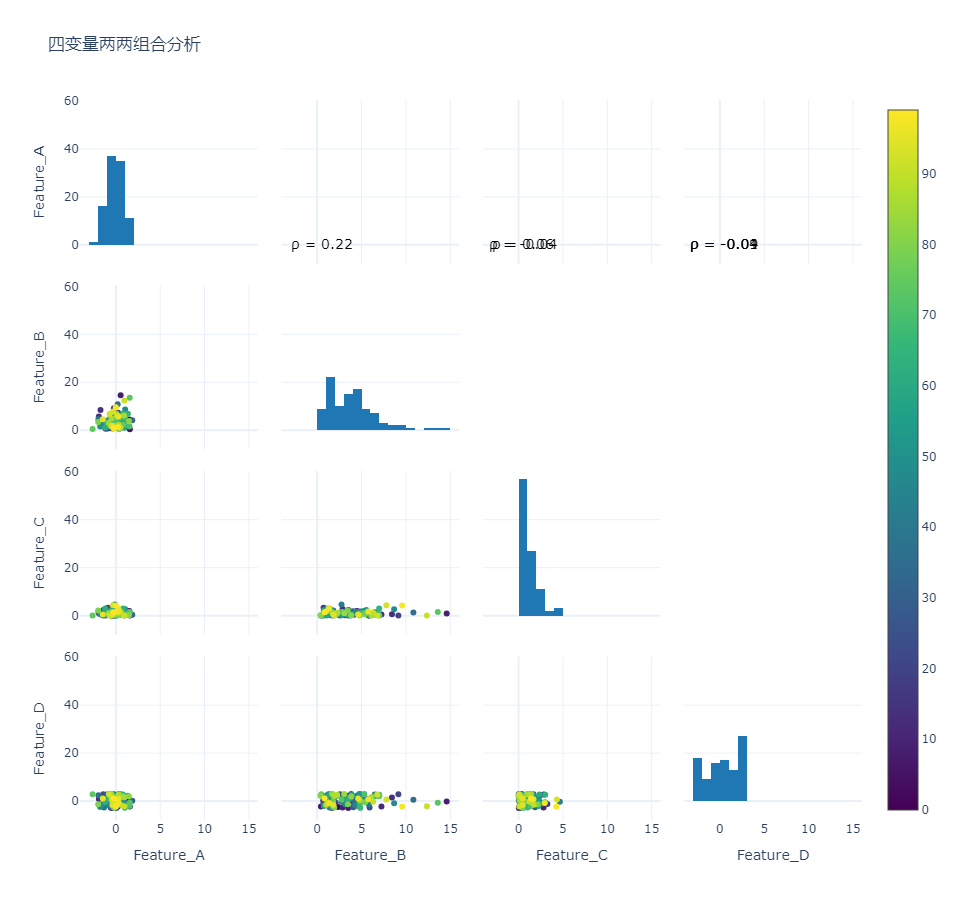

In [18]:
#方法二：使用 make_subplots 手动创建 (更灵活)
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# 获取列名
columns = df.columns
n = len(columns)

# 创建子图画布 (4x4网格)
fig = make_subplots(
    rows=n, cols=n,
    shared_xaxes='all',  # 共享X轴
    shared_yaxes='all',  # 共享Y轴
    vertical_spacing=0.03,
    horizontal_spacing=0.03
)

# 填充散点图
for i, y_col in enumerate(columns, 1):
    for j, x_col in enumerate(columns, 1):
        # 对角线位置添加直方图
        if i == j:
            hist = go.Histogram(
                x=df[x_col],
                name=f"{x_col}分布",
                marker_color='#1f77b4',
                nbinsx=20
            )
            fig.add_trace(hist, row=i, col=j)
        # 下三角区域添加散点图
        elif i > j:
            scatter = go.Scatter(
                x=df[x_col],
                y=df[y_col],
                mode='markers',
                name=f"{x_col} vs {y_col}",
                marker=dict(
                    size=6,
                    color=df.index,  # 使用索引作为颜色
                    colorscale='Viridis',
                    showscale=(i==n and j==1)  # 只在左下角显示色标
                ),
                text=[f"索引: {idx}" for idx in df.index]  # 悬停文本
            )
            fig.add_trace(scatter, row=i, col=j)
        # 上三角区域留空或添加相关系数
        else:
            # 计算相关系数
            corr = df[[x_col, y_col]].corr().iloc[0,1]
            # 添加文本注释
            fig.add_annotation(
                xref=f"x{j}", yref=f"y{i}",
                x=0.5, y=0.5,
                text=f"ρ = {corr:.2f}",
                showarrow=False,
                font=dict(size=14, color='red' if abs(corr) > 0.5 else 'black'),
                row=i, col=j
            )

# 设置坐标轴标签
for i, col in enumerate(columns, 1):
    fig.update_xaxes(title_text=col, row=n, col=i)
    fig.update_yaxes(title_text=col, row=i, col=1)

# 更新布局
fig.update_layout(
    title_text="四变量两两组合分析",
    height=900,
    showlegend=False,
    template='plotly_white',
    hovermode='closest'
)

# 隐藏重复的坐标轴标签
for i in range(1, n+1):
    for j in range(1, n+1):
        if i < n:  # 隐藏底部行的上方X轴标签
            fig.update_xaxes(showticklabels=False, row=i, col=j)
        if j > 1:  # 隐藏左侧列的右侧Y轴标签
            fig.update_yaxes(showticklabels=False, row=i, col=j)

fig.show()

In [19]:
#方法三：使用 Plotly Figure Factory (专业统计可视化)
import plotly.figure_factory as ff

# 创建带趋势线的散点图矩阵
fig = ff.create_scatterplotmatrix(
    df,
    diag='histogram',  # 对角线显示直方图
    index='index',     # 使用索引作为标识
    height=800,
    width=800,
    title='四变量相关分析'
)

# 添加回归线
for i in range(len(fig.data)):
    if 'histogram' not in fig.data[i].name:
        fig.data[i].update(
            mode='markers+lines',  # 添加趋势线
            line=dict(
                color='rgba(255,0,0,0.3)',
                width=2,
                dash='dash'
            )
        )

# 添加相关系数
annotations = []
for i, yi in enumerate(df.columns):
    for j, xj in enumerate(df.columns):
        if i != j:
            corr = df[[xj, yi]].corr().iloc[0,1]
            annotations.append(dict(
                xref=f'x{j+1}', yref=f'y{i+1}',
                x=0.5, y=0.9,
                text=f'ρ={corr:.2f}',
                showarrow=False,
                font=dict(size=12, color='red' if abs(corr)>0.7 else 'black')
            ))
fig.update_layout(annotations=annotations)

fig.show()


PlotlyError: Make sure you set the index input variable to one of the column names of your dataframe.

In [21]:
15 if 1==2 else 10

10

In [22]:
#方法四：交互式关联分析 (高级)
from ipywidgets import interact, Dropdown
import plotly.graph_objects as go

# 创建下拉选择器
@interact
def interactive_scatter(
    x_axis=Dropdown(options=df.columns, value='Feature_A', description='X轴:'),
    y_axis=Dropdown(options=df.columns, value='Feature_B', description='Y轴:'),
    size_by=Dropdown(options=[None] + list(df.columns)), 
    color_by=Dropdown(options=[None] + list(df.columns))
):
    # 创建基础散点图
    fig = go.Figure()
    
    # 设置点大小和颜色
    size = df[size_by] * 5 + 5 if size_by else 8
    color = df[color_by] if color_by else '#1f77b4'
    
    # 添加散点图
    fig.add_trace(go.Scatter(
        x=df[x_axis],
        y=df[y_axis],
        mode='markers',
        marker=dict(
            size=size,
            color=color,
            colorscale='Viridis' if color_by else None,
            showscale=bool(color_by),
        text=df.index,
        hoverinfo='text+x+y'
    ))
    
    # 添加回归线
    coefficients = np.polyfit(df[x_axis], df[y_axis], 1)
    trendline = np.poly1d(coefficients)
    fig.add_trace(go.Scatter(
        x=np.linspace(df[x_axis].min(), df[x_axis].max(), 100),
        y=trendline(np.linspace(df[x_axis].min(), df[x_axis].max(), 100)),
        mode='lines',
        line=dict(color='red', width=2, dash='dash'),
        name=f'趋势线: y={coefficients[0]:.2f}x+{coefficients[1]:.2f}'
    ))
    
    # 更新布局
    fig.update_layout(
        title=f'{x_axis} vs {y_axis} 关系分析',
        xaxis_title=x_axis,
        yaxis_title=y_axis,
        height=600,
        template='plotly_white'
    )
    fig.show()

SyntaxError: invalid syntax (3272956206.py, line 35)

In [23]:
#1. 添加统计信息
# 在方法二的基础上添加回归线
for i in range(1, n+1):
    for j in range(1, n+1):
        if i > j:  # 下三角区域
            y_col = columns[i-1]
            x_col = columns[j-1]
            
            # 添加回归线
            coefficients = np.polyfit(df[x_col], df[y_col], 1)
            trendline = np.poly1d(coefficients)
            x_range = [df[x_col].min(), df[x_col].max()]
            fig.add_trace(go.Scatter(
                x=x_range,
                y=trendline(x_range),
                mode='lines',
                line=dict(color='red', width=2),
                showlegend=False
            ), row=i, col=j)
            
            # 添加R²值
            r_squared = np.corrcoef(df[x_col], df[y_col])[0,1]**2
            fig.add_annotation(
                xref=f"x{j}", yref=f"y{i}",
                x=0.05, y=0.95,
                text=f"R² = {r_squared:.2f}",
                showarrow=False,
                font=dict(size=12, color='red'),
                row=i, col=j
            )

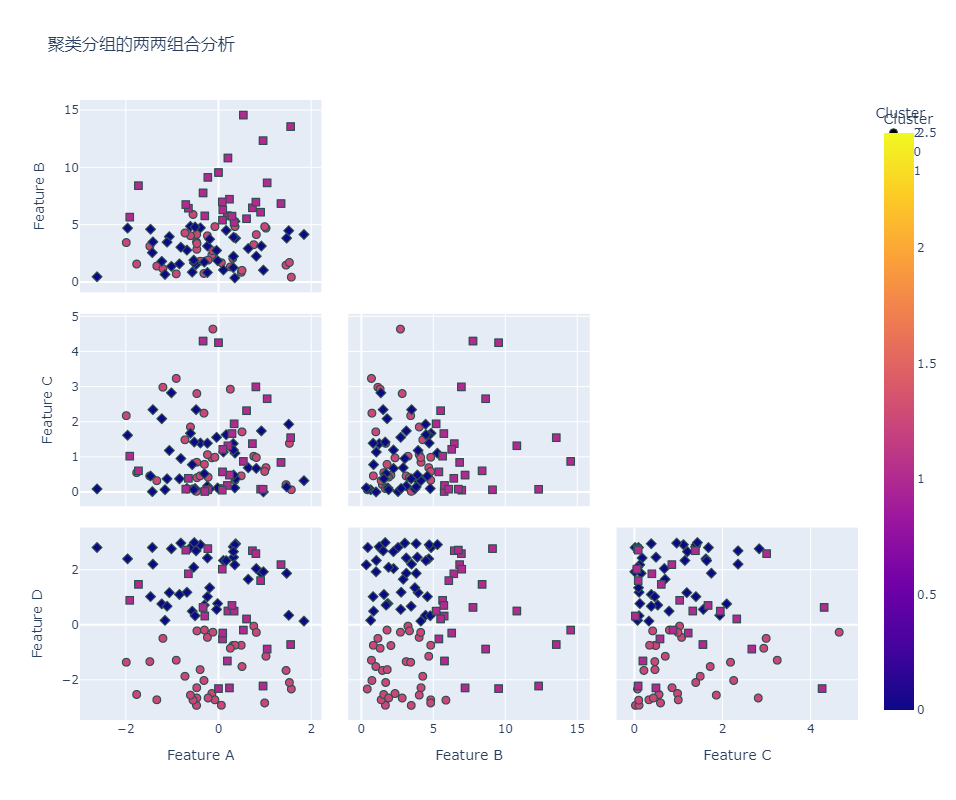

In [24]:
#2. 聚类分组可视化
from sklearn.cluster import KMeans

# 添加聚类分组
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(df[columns])

# 在散点图中使用聚类分组
fig = px.scatter_matrix(
    df,
    dimensions=columns,
    color='Cluster',  # 按聚类着色
    symbol='Cluster',  # 按聚类使用不同形状
    title="聚类分组的两两组合分析",
    labels={col: col.replace('_', ' ') for col in columns},
    height=800
)

# 自定义聚类样式
fig.update_traces(
    marker=dict(size=8, line=dict(width=1, color='DarkSlateGrey')),
    diagonal_visible=False,
    showupperhalf=False
)
fig.show()

In [25]:
#3. 性能优化 (大数据集)
# 使用WebGL加速渲染
fig = px.scatter_matrix(
    df,
    dimensions=columns,
    render_mode='webgl',  # 启用WebGL加速
    title="大数据集优化",
    height=800
)

# 或者使用专门的WebGL函数
from plotly.express import scatter_gl
fig = scatter_gl(
    df, 
    x='Feature_A', 
    y='Feature_B',
    # 其他参数...
)




TypeError: scatter_matrix() got an unexpected keyword argument 'render_mode'

In [26]:
#4. 导出和分享
# 导出为HTML
fig.write_html("scatter_matrix.html")

# 导出为图片 (需要安装kaleido)
fig.write_image("scatter_matrix.png", width=1200, height=1200)

# 在线分享
import chart_studio
chart_studio.tools.set_credentials_file(username='your_username', api_key='your_api_key')
py.plot(fig, filename='scatter-matrix', auto_open=True)

ValueError: 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido


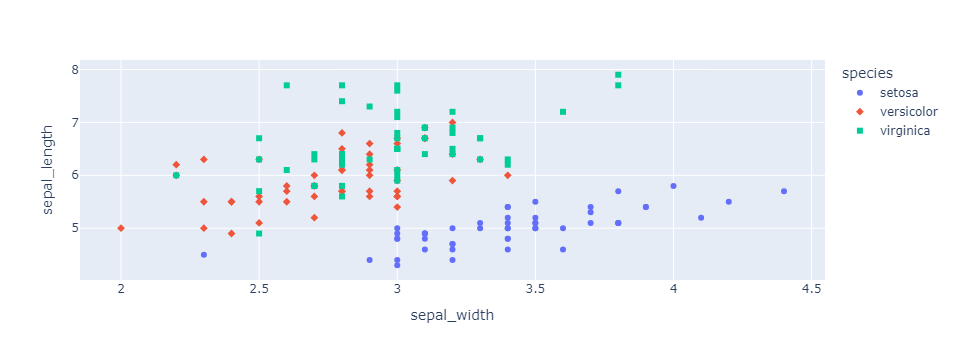

In [27]:
#形状参数的基本用法
import plotly.express as px
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length", 
                 color="species", 
                 symbol="species")  # 不同种类使用不同形状
fig.show()

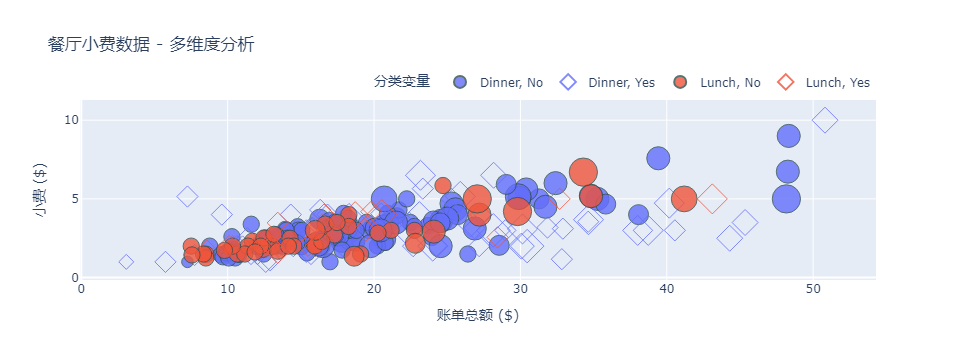

In [29]:
import plotly.express as px

# 加载数据集
df = px.data.tips()

# 创建散点图
fig = px.scatter(
    df,
    x="total_bill",
    y="tip",
    color="time",        # 颜色区分午餐/晚餐
    symbol="smoker",     # 形状区分是否吸烟
    symbol_sequence=["circle", "diamond-open"],  # 自定义形状
    size="size",         # 大小表示人数
    hover_data=["day", "sex"],  # 悬停额外信息
    title="餐厅小费数据 - 多维度分析",
    labels={
        "total_bill": "账单总额 ($)",
        "tip": "小费 ($)",
        "time": "用餐时间",
        "smoker": "是否吸烟"
    }
)

# 自定义样式
fig.update_traces(
    marker=dict(
        line=dict(width=1, color='DarkSlateGrey'),
        opacity=0.8
    )
)

# 更新布局
fig.update_layout(
    legend_title_text="分类变量",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    )
)

fig.show()